# Keypoint detectors: visual check
Plots the keypoints of one image for all the detectors in one figure.

In [13]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt

from utils import load_images
from keypoints_3 import detect, anms

In [14]:
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"
QSD1_DIR = DATA_DIR / "qsd1_w4"

db_ids, db_images = load_images(DATA_DIR / "BBDD")
query_ids, query_images = load_images(QSD1_DIR)

In [15]:
IMAGE_INDEX = 6
METHODS = ["dog", "harris_laplace", "hessian_laplace", "fast", "dense", "hybrid"]
MAX_KPS = 500
CLAHE = False
N_SHOW = 100            # keypoints drawn (ANMS picks the strongest and best spread); None = all

PARAMS = {
    "dog": {
        "contrast": 0.04,
        "edge": 10,
        "sigma": 1.6,
    },
    "harris_laplace": {
        "n_scales": 8,
        "sigma0": 1.6,
        "k": 1.4,
        "harris_thr": 1e-6,
        "log_thr": 0.01,
        "alpha": 0.04,
    },
    "hessian_laplace": {
        "n_scales": 8,
        "sigma0": 1.6,
        "k": 1.4,
        "det_thr": 2e-4,
        "log_thr": 0.01,
        "edge": 10,
    },
    "fast": {
        "thr": 20,
        "n_levels": 4,
        "ratio": 1.5,
        "sigma0": 2.0,
    }
}

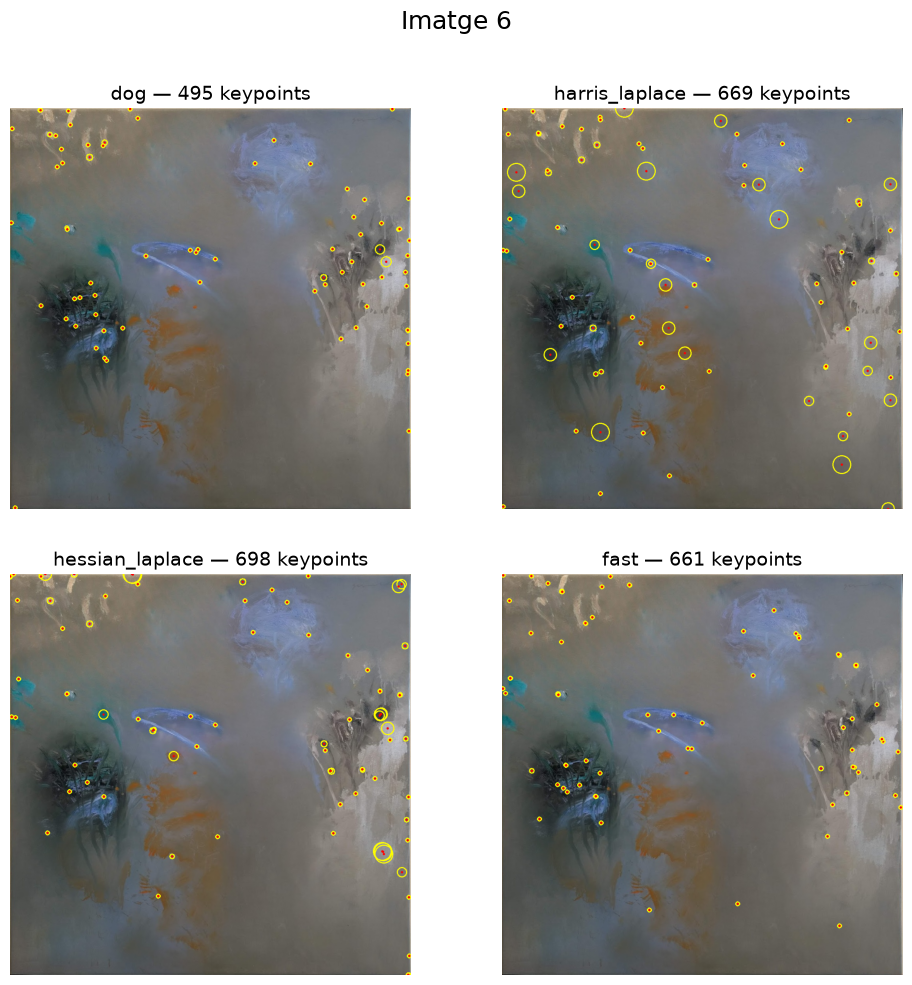

In [17]:
image = db_images[IMAGE_INDEX]

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for ax, method in zip(axes.ravel(), METHODS):
    keypoints = detect(image, method=method, max_kps=MAX_KPS, clahe=CLAHE, **PARAMS[method])

    image_with_keypoints = image.copy()
    for kp in anms(keypoints, N_SHOW):
        x, y = map(int, kp.pt)
        radius = max(5, int(kp.size / 2))
        cv2.circle(image_with_keypoints, (x, y), radius, (0, 255, 255), 2)
        cv2.circle(image_with_keypoints, (x, y), 3, (0, 0, 255), -1)

    ax.imshow(cv2.cvtColor(image_with_keypoints, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{method} — {len(keypoints)} keypoints", fontsize=14)
    ax.axis("off")

fig.suptitle(f"Imatge {IMAGE_INDEX}", fontsize=18)
plt.tight_layout(h_pad=3, rect=(0, 0, 1, 0.96))
plt.show()